# Image Mining — Practical Work on Content-based image retrieval (CBIR) and Shot-cut detection
**Part 1:** content-based image retrieval (CBIR) on *Vertigo*.


**Part 2:** shot-cut detection, developed on *Matrix*, evaluated zero-shot on *Cosmos Laundromat*, then checked on the three other provided clips (hand-annotated).

## Environment and how to run

| Item | Value |
|---|---|
| Python | 3.13.5 (macOS, CPU only, no GPU needed) |
| Packages | see `requirements.txt` (`av`, `numpy`, `pillow`, `matplotlib`, `torch`, `torchvision`, `ipywidgets`) |
| Data | included in this folder: the five clips in `videos_clips/` and `Portrait_of_a_Lady.jpg` next to this notebook. Paths are relative, so run the notebook from this folder |
| Weights | ResNet-50 `IMAGENET1K_V2` (torchvision) and DINOv2 ViT-S/14 (`torch.hub`) are downloaded on first run |

```bash
python -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
jupyter lab CBIR_ShotCut_Detection.ipynb
```

In [1]:
# All imports in one place
import time
from pathlib import Path

import av
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision import transforms
from torchvision.models import ResNet50_Weights, resnet50

torch.manual_seed(0)

VIDEO_DIR = Path("videos_clips")
VERTIGO = VIDEO_DIR / "Extrait3-Vertigo-Dream_Scene(320p).m4v"
MATRIX = VIDEO_DIR / "Extrait5-Matrix-Helicopter_Scene(280p).m4v"
COSMOS = VIDEO_DIR / "Extrait1-Cosmos_Laundromat1(340p).m4v"
PORTRAIT = "Portrait_of_a_Lady.jpg"
for p in (VERTIGO, MATRIX, COSMOS):
    assert p.exists(), f"missing input file: {p}"

# 1. Content-based image retrieval

The task: given a **query image**, rank a fixed set of video frames (the **gallery**) from the most to the least
similar, and check whether the ranking retrieves the expected kind of visual relation. I use the *Vertigo*
dream sequence (*Extrait3-Vertigo-Dream_Scene*, extracted from Alfred Hitchcock's 1958 film), because it mixes
very different looks: dark shots, strong colour casts (blue, purple, red), close-ups of faces, an animated
sequence and bright backgrounds. 

The steps are:  
- [1.1 metadata](#11-video-metadata)
- [1.2 gallery](#12-gallery-150-frames-sampled-uniformly-from-2-s-to-duration--2-s)
- [1.3 queries](#13-query-images)
- [1.4 representations](#14-representations)
- [1.5 ranking](#15-ranking)
- [1.6 evaluation](#16-metric-evaluation-computed-not-read-off-the-figures)

## 1.1 Video metadata

Before sampling anything, I read the basic properties of the video with PyAV: the **duration** (the stream
duration is expressed in the stream *time base*, so it must be multiplied by `stream.time_base` to get seconds),
the **number of frames** and the resulting **frame rate** (frames / duration), plus the image size.

These values are needed for two reasons. First, the gallery is defined in *seconds* (from 2 s after the start to
2 s before the end), so the duration is needed to place the samples. Second, later steps convert between
**frame indices** and **timestamps** (for example the held-out criterion uses a time window of ±1 s, and the shot-cut
part works in frames), so I want to check these two scales are consistent. I also print the metadata of
*Matrix* and *Cosmos* (used in Part 2) to see that the clips have different sizes and frame rates (23.98 to 25 fps):
nothing in the code may assume a fixed resolution or frame rate.

In [2]:
def video_metadata(path):
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        duration_s = float(stream.duration * stream.time_base)
        frame_count = int(stream.frames)
        return dict(duration_s=duration_s, frame_count=frame_count,
                    fps=frame_count / duration_s, width=stream.width, height=stream.height)

for name, path in [("Vertigo", VERTIGO), ("Matrix", MATRIX), ("Cosmos", COSMOS)]:
    m = video_metadata(path)
    print(f"{name:8s} {m['width']}x{m['height']}  {m['frame_count']} frames  "
          f"{m['duration_s']:.2f} s  {m['fps']:.2f} fps")

duration_s = video_metadata(VERTIGO)["duration_s"]

Vertigo  560x320  2375 frames  95.00 s  25.00 fps
Matrix   640x280  768 frames  32.03 s  23.98 fps
Cosmos   812x340  3168 frames  132.00 s  24.00 fps


## 1.2 Gallery (150 frames sampled uniformly from 2 s to duration − 2 s)

**Why a gallery.** Searching every frame of the clip would be slow for the deep models, and consecutive frames
are almost identical, so most of the work would be redundant. Instead I build a **fixed, sampled subset** of
150 frames once, and every representation (histogram, ResNet-50, DINOv2) is evaluated on exactly the same images.
This also makes the comparison fair: any difference in the results comes from the representation or the metric,
not from the choice of frames.

**How it is built.**
- The 150 target times are equally spaced between 2 s and `duration − 2 s` (`np.linspace`). Leaving out the first
  and last 2 s avoids the dark opening of the clip (the first frames are almost black) and its very last frames. The spacing is `(duration − 4 s) / 149`,
  i.e. about 0.6 s, or roughly 15 frames, between two gallery frames.
- The video is decoded **once, in order**. For each target time, I keep the first frame whose timestamp is greater
  than or equal to the target, so the real timestamp is equal to, or slightly after, the target (the first
  gallery frame is frame 50 = 2 s × 25 fps and the last one is frame 2325).
- For each kept frame I store its **gallery id** (`vertigo_000` … `vertigo_149`), the RGB image, its **frame index**
  and its **timestamp**. This metadata is what the retrieval panels display later.

**Consequence for the queries.** Since only one frame in about 15 is in the gallery, a frame that is *not* in
the gallery always has near-duplicate neighbours in it. This is exactly what makes the *held-out crop* query
(frame 350) meaningful: the system cannot find the source frame, it has to retrieve its temporal neighbours.

I also decode frames 350 and 356 in the same pass, so the video is read only once. The cell ends with
`assert` checks instead of assumptions: the gallery has 150 images, `vertigo_020` is frame 356 (14.24 s), and
frame 350 is **not** in the gallery.

In [3]:
gallery_size = 150
target_times_s = np.linspace(2.0, duration_s - 2.0, gallery_size)

gallery, extra_frames = [], {}
next_target = 0
with av.open(str(VERTIGO)) as container:
    for frame_index, frame in enumerate(container.decode(video=0)):
        if frame_index in (350, 356):
            extra_frames[frame_index] = frame.to_ndarray(format="rgb24")
        if next_target == gallery_size:
            break
        timestamp_s = float(frame.time)
        if timestamp_s >= target_times_s[next_target]:
            gallery.append({"gallery_id": f"vertigo_{next_target:03d}",
                            "image": frame.to_ndarray(format="rgb24"),
                            "frame_index": frame_index, "timestamp_s": timestamp_s})
            next_target += 1

G_FRAME = np.array([g["frame_index"] for g in gallery])
G_TIME = np.array([g["timestamp_s"] for g in gallery])
G_PIL = [Image.fromarray(g["image"]) for g in gallery]

# Sanity checks instead of assumptions
assert len(gallery) == gallery_size
assert gallery[20]["frame_index"] == 356 and gallery[20]["gallery_id"] == "vertigo_020"
assert 350 not in G_FRAME, "the held-out frame must not be in the gallery"
print(f"gallery: {len(gallery)} frames, frame range {G_FRAME[0]}..{G_FRAME[-1]}, "
      f"vertigo_020 = frame {gallery[20]['frame_index']} @ {gallery[20]['timestamp_s']:.2f} s")

gallery: 150 frames, frame range 50..2325, vertigo_020 = frame 356 @ 14.24 s


## 1.3 Query images

I use four queries of increasing difficulty. Each one tests a different property of the representation, and each
has an expected answer that is checked automatically in section 1.6.

| # | Query | What it tests | Expected result |
|---|---|---|---|
| 1 | **Whole frame**: the complete frame 356 (`vertigo_020`, 14.24 s) | Pipeline sanity: the query *is* a gallery image, so any correct implementation must find it | Rank 1 = frame 356 |
| 2 | **In-gallery crop**: a 200×200 region of `vertigo_020` | Retrieval from *partial* content: only the face of the sleeping man (blue tint) is visible | Rank 1 = frame 356 |
| 3 | **Held-out crop**: the same region cut from frame 350, which is **not** in the gallery | Generalisation: the exact source frame is excluded, so the system should return *visually similar neighbours* | One of ranks 1–3 within 1 s of 14.00 s (13–15 s) |
| 4 | **External image**: *Portrait of a Lady* by Bernardino Zaganelli (949×1300 px) | **Semantic** similarity across a large domain gap (painting vs. film): a woman wearing a pendant | One of ranks 1–3 with a frame index in 1184–1350 (woman with a pendant on a clear background) |

The crop box is `(left, top, right, bottom) = (160, 40, 360, 240)` of the original 560×320 frame. Two points are
worth noticing here, because they come back in the results:

- **Different sizes.** A crop is 200×200 px while gallery frames are 560×320 px, so queries and gallery images
  do *not* have the same size. A representation must either be insensitive to size (a normalised histogram) or
  I must be careful about the scale at which images are given to a network (see 1.4).
- **Increasing difficulty.** Query 1 only checks the code. Query 2 removes most of the frame but its source
  is in the gallery. Query 3 also removes the source frame. Query 4 shares *no pixels* with the video, so a
  method based on colour statistics alone should struggle.

The cell below shows the four queries with their sizes.

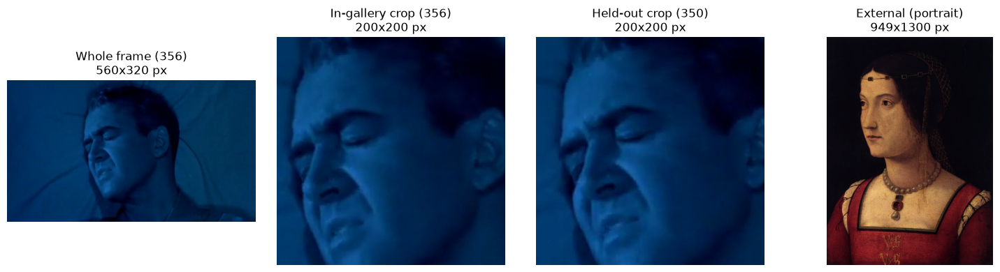

In [4]:
crop_box = (160, 40, 360, 240)  # left, top, right, bottom

assert np.array_equal(extra_frames[356], gallery[20]["image"])
whole_frame_query = Image.fromarray(extra_frames[356])
queries = {
    "Whole frame (356)": whole_frame_query,
    "In-gallery crop (356)": whole_frame_query.crop(crop_box),
    "Held-out crop (350)": Image.fromarray(extra_frames[350]).crop(crop_box),
    "External (portrait)": Image.open(PORTRAIT).convert("RGB"),
}

fig, axs = plt.subplots(1, 4, figsize=(15, 4))
for ax, (name, img) in zip(axs, queries.items()):
    ax.imshow(img); ax.set_title(f"{name}\n{img.size[0]}x{img.size[1]} px"); ax.axis("off")
plt.tight_layout(); plt.show()

## 1.4 Representations

All images go through **the same function** for a given representation, whether they are queries or gallery frames.

### (a) Global colour histogram
A joint RGB histogram with 8 bins per channel (512-D), L1-normalised so that a 200×200 crop and a 560×320 frame
can be compared. It has no spatial information: it only records *which colours* appear and *how often*.

Because a histogram is a probability distribution, I compare it with four measures: cosine,
histogram intersection, Bhattacharyya coefficient and χ². Section 1.6 shows that the choice of measure does
not change the pass/fail outcome. The representation is the limiting factor, not the measure.

In [5]:
def color_histogram(image, bins=8):
    pixels = np.asarray(image).reshape(-1, 3)
    hist, _ = np.histogramdd(pixels, bins=[bins] * 3, range=[(0, 256)] * 3)
    hist = hist.ravel()
    return hist / hist.sum()

# similarity(query_vector, gallery_matrix) -> one score per gallery item, higher = more similar
def sim_cosine(q, G):
    return (G @ q) / (np.linalg.norm(G, axis=1) * np.linalg.norm(q) + 1e-12)
def sim_intersection(q, G):
    return np.minimum(G, q).sum(axis=1)
def sim_bhattacharyya(q, G):
    return np.sqrt(G * q).sum(axis=1)
def sim_neg_chi2(q, G):
    return -0.5 * ((G - q) ** 2 / (G + q + 1e-12)).sum(axis=1)

t0 = time.perf_counter()
hist_gallery = np.stack([color_histogram(g["image"]) for g in gallery])
timings = {"Colour histogram": time.perf_counter() - t0}
hist_queries = {n: color_histogram(img) for n, img in queries.items()}
print("histogram gallery:", hist_gallery.shape, f"({timings['Colour histogram']:.2f} s)")

histogram gallery: (150, 512) (0.66 s)


### (b) ResNet-50 (ImageNet-1K V2): official preprocessing vs scale-consistent preprocessing

The official `weights.transforms()` **resizes the short side to 232 px and centre-crops 224×224**. That transform
was designed for ImageNet classification, and here it causes two problems:

1. **Different scale for crops and frames.** A gallery frame (560×320) is *shrunk* by 232/320 = 0.73,
   but a 200×200 crop is *enlarged* by 232/200 = 1.16. So the sleeping man's face is about 1.6× bigger in the
   query tensor than in the gallery tensor. CNN features are not scale invariant, so the face in the query
   and the face in the frame no longer look alike to the network.
2. **Lost borders.** The centre crop keeps only the middle 224 of 406 columns, so 45 % of every 16:9 frame is discarded.

**Improvement:** ResNet-50 is fully convolutional up to `avgpool`, so it accepts any input size.
I feed every image **at the pixel scale of the video**:
- gallery frames and video crops are kept at their native resolution;
- an external image larger than the video frame (the portrait is 949×1300) is resized so its short side equals
  the video frame height (320 px).

Global average pooling then gives a 2048-D vector whatever the input size. The only image-specific step is the
ImageNet mean/std normalisation, which is identical for query and gallery.

In [6]:
weights = ResNet50_Weights.IMAGENET1K_V2
resnet = resnet50(weights=weights)
resnet.fc = torch.nn.Identity()           # 1000 logits -> 2048-D representation
resnet.eval()

official_preprocess = weights.transforms()
to_normalized_tensor = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])
VIDEO_HEIGHT = gallery[0]["image"].shape[0]   # 320

def to_video_scale(img):
    # Downscale images larger than a video frame so their short side matches the frame height
    w, h = img.size
    if min(w, h) <= VIDEO_HEIGHT:
        return img
    s = VIDEO_HEIGHT / min(w, h)
    return img.resize((round(w * s), round(h * s)), Image.BILINEAR)

@torch.inference_mode()
def embed_batched(model, preprocess, images, batch_size=16):
    return torch.cat([model(torch.stack([preprocess(im) for im in images[i:i + batch_size]]))
                      for i in range(0, len(images), batch_size)]).numpy()

@torch.inference_mode()
def embed_one_by_one(model, preprocess, images):
    # Native-size inputs differ in shape, so they cannot be stacked into one batch
    return np.stack([model(preprocess(im)[None])[0].numpy() for im in images])

t0 = time.perf_counter()
resnet_official_gallery = embed_batched(resnet, official_preprocess, G_PIL)
timings["ResNet-50 official (224 crop)"] = time.perf_counter() - t0

t0 = time.perf_counter()
resnet_native_gallery = embed_one_by_one(resnet, to_normalized_tensor, G_PIL)
timings["ResNet-50 native scale"] = time.perf_counter() - t0

resnet_official_queries = {n: embed_batched(resnet, official_preprocess, [im])[0] for n, im in queries.items()}
resnet_native_queries = {n: embed_one_by_one(resnet, to_normalized_tensor, [to_video_scale(im)])[0]
                         for n, im in queries.items()}
print("ResNet galleries:", resnet_official_gallery.shape, resnet_native_gallery.shape)

ResNet galleries: (150, 2048) (150, 2048)


### (c) Optional: DINOv2 ViT-S/14

**Hypothesis (stated before looking at the results).** DINOv2 is trained with self-supervision rather than
ImageNet labels, so its features should be more "semantic". It should therefore do *at least as well as*
ResNet-50 on the external portrait query, where the task is to find a woman with a pendant despite a painting
vs film domain gap.

I use the standard DINOv2 evaluation preprocessing (resize 256, centre-crop 224), so it has the same scale
problem as the official ResNet transform. I kept it as is, to show what that preprocessing costs.

In [7]:
dino_transform = transforms.Compose([
    transforms.Resize(256, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])
try:
    dino = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14", verbose=False).eval()
    t0 = time.perf_counter()
    dino_gallery = embed_batched(dino, dino_transform, G_PIL)
    timings["DINOv2 ViT-S/14 (224 crop)"] = time.perf_counter() - t0
    dino_queries = {n: embed_batched(dino, dino_transform, [im])[0] for n, im in queries.items()}
except Exception as e:                      # e.g. no internet on first run
    print("DINOv2 skipped:", e)
    dino = None

n_params = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
print(f"ResNet-50: {n_params(resnet):.1f} M parameters"
      + (f" | DINOv2 ViT-S/14: {n_params(dino):.1f} M parameters" if dino is not None else ""))

/Users/sandyjingjing/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/Users/sandyjingjing/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/Users/sandyjingjing/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


ResNet-50: 23.5 M parameters | DINOv2 ViT-S/14: 22.1 M parameters


In [8]:
# Fair timing: warm-up first, same 32 frames, one image at a time for every encoder
# (on my CPU, batches of 16 were ~4x slower per image than single images)

def time_encoder(encode, model, preprocess, images, n_warmup=2):
    encode(model, preprocess, images[:n_warmup])          # warm-up, not timed
    t0 = time.perf_counter()
    encode(model, preprocess, images)
    return 1000 * (time.perf_counter() - t0) / len(images)  # ms / frame

subset = G_PIL[:32]
print(f"ResNet-50 official (224 crop): {time_encoder(embed_one_by_one, resnet, official_preprocess, subset):6.1f} ms/frame")
print(f"ResNet-50 native scale       : {time_encoder(embed_one_by_one, resnet, to_normalized_tensor, subset):6.1f} ms/frame")
if dino is not None:
    print(f"DINOv2 ViT-S/14 (224 crop)   : {time_encoder(embed_one_by_one, dino,   dino_transform,      subset):6.1f} ms/frame")


ResNet-50 official (224 crop):   35.2 ms/frame
ResNet-50 native scale       :  116.1 ms/frame
DINOv2 ViT-S/14 (224 crop)   :   40.3 ms/frame


## 1.5 Ranking

**Metric for deep features: cosine similarity.** After global average pooling, the norm of a CNN or ViT
embedding mostly reflects how strongly the network is activated overall (contrast, texture amount), while the
*direction* encodes *which* features are present. Cosine compares only the direction. This is the standard choice
for retrieval with these embeddings and is equivalent to Euclidean distance on L2-normalised vectors.

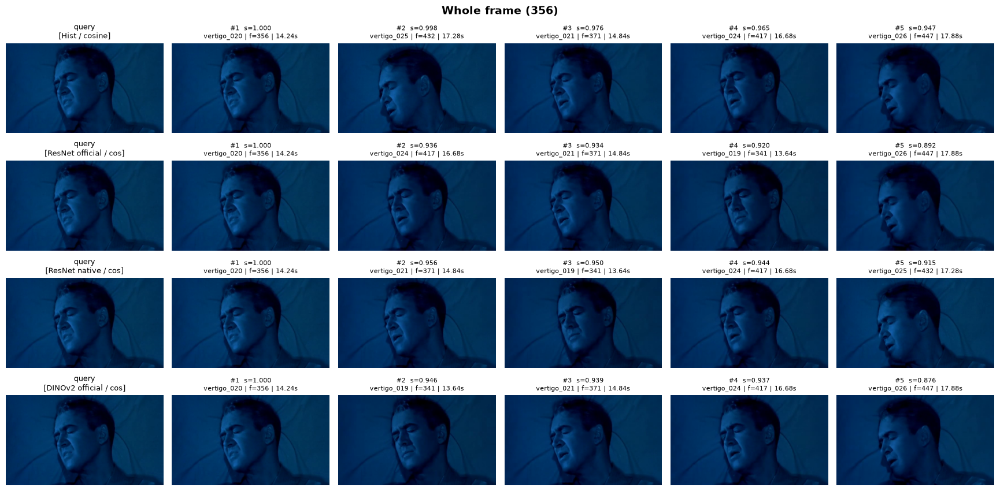

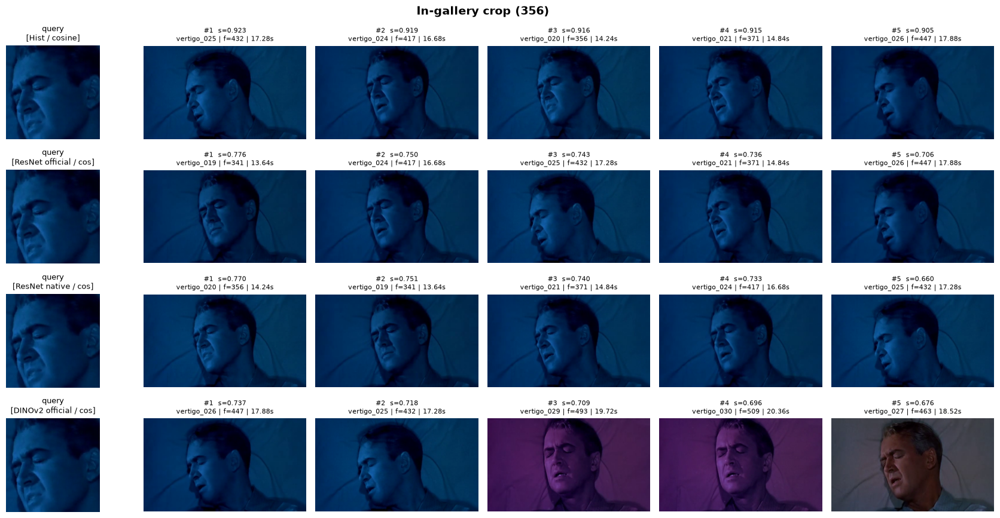

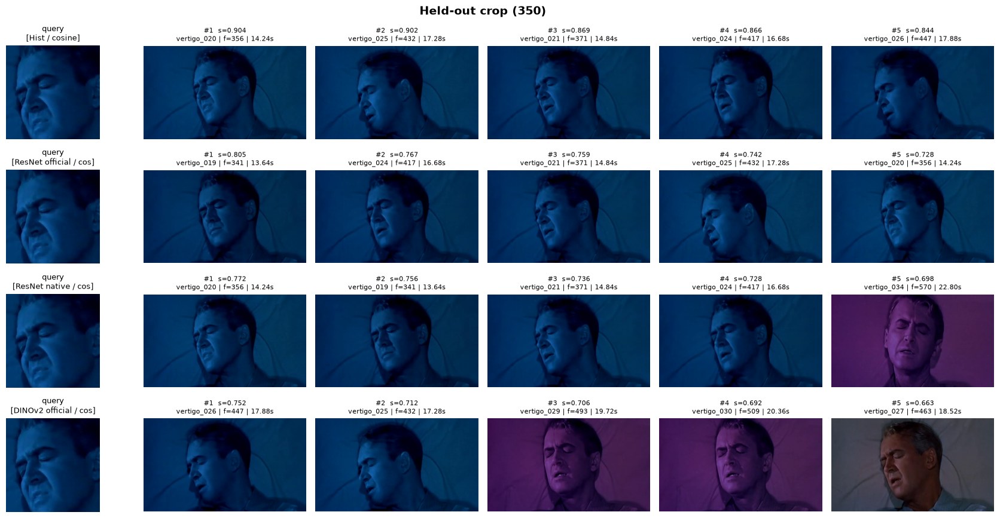

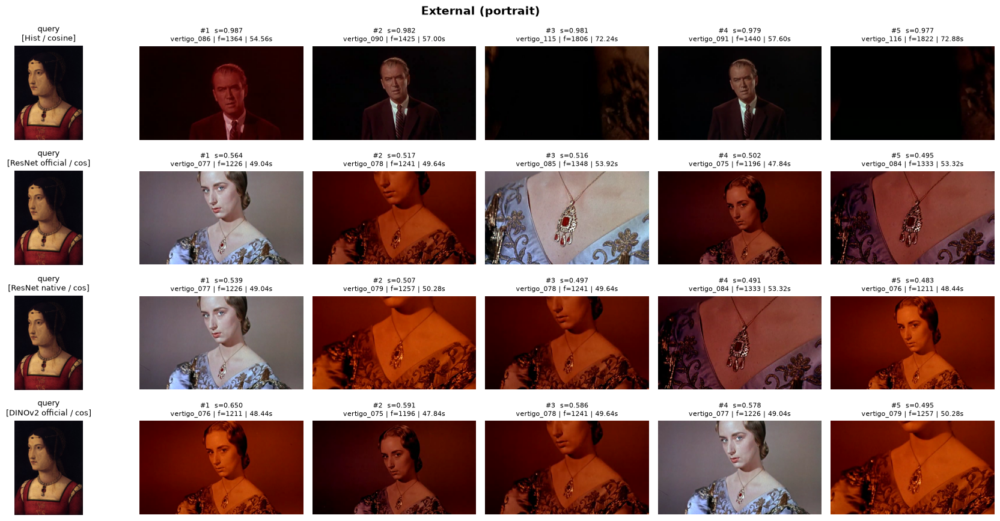

In [9]:
def rank_gallery(q, G, sim):
    scores = sim(q, G)
    order = np.argsort(-scores, kind="stable")
    return order, scores[order]

def show_panel(query_img, rows, title, k=5):
    # rows: list of (method_name, order, sorted_scores)
    fig, axes = plt.subplots(len(rows), k + 1, figsize=(2.9 * (k + 1), 2.2 * len(rows)))
    fig.suptitle(title, fontsize=14, fontweight="bold")
    for r, (name, order, scores) in enumerate(rows):
        axes[r, 0].imshow(query_img); axes[r, 0].set_title(f"query\n[{name}]", fontsize=9)
        for i in range(k):
            g = gallery[order[i]]
            axes[r, i + 1].imshow(g["image"])
            axes[r, i + 1].set_title(f"#{i + 1}  s={scores[i]:.3f}\n{g['gallery_id']} | f={g['frame_index']}"
                                     f" | {g['timestamp_s']:.2f}s", fontsize=8)
        for ax in axes[r]: ax.axis("off")
    plt.tight_layout(); plt.show()

methods = {
    "Hist / cosine":           (hist_queries, hist_gallery, sim_cosine),
    "Hist / intersection":     (hist_queries, hist_gallery, sim_intersection),
    "Hist / Bhattacharyya":    (hist_queries, hist_gallery, sim_bhattacharyya),
    "Hist / -chi2":            (hist_queries, hist_gallery, sim_neg_chi2),
    "ResNet official / cos":   (resnet_official_queries, resnet_official_gallery, sim_cosine),
    "ResNet native / cos":     (resnet_native_queries, resnet_native_gallery, sim_cosine),
}
if dino is not None:
    methods["DINOv2 official / cos"] = (dino_queries, dino_gallery, sim_cosine)

rankings = {(m, q): rank_gallery(Q[q], G, s) for m, (Q, G, s) in methods.items() for q in queries}

shown = ["Hist / cosine", "ResNet official / cos", "ResNet native / cos"] + \
        (["DINOv2 official / cos"] if dino is not None else [])
for qname, qimg in queries.items():
    show_panel(qimg, [(m, *rankings[(m, qname)]) for m in shown], qname)

## 1.6 Metric evaluation (computed, not read off the figures)

In [10]:
def criterion(qname, order):
    if qname.startswith(("Whole", "In-gallery")):
        return G_FRAME[order[0]] == 356
    if qname.startswith("Held-out"):
        return bool(np.any(np.abs(G_TIME[order[:3]] - 14.00) < 1.0))
    return bool(np.any((G_FRAME[order[:3]] >= 1184) & (G_FRAME[order[:3]] <= 1350)))

print(f"{'method':24s} {'query':22s} {'result':6s} {'rank of 356':>11s}   top-5 frame indices")
summary = {}
for m in methods:
    for q in queries:
        order, _ = rankings[(m, q)]
        ok = criterion(q, order)
        summary.setdefault(m, []).append(ok)
        r356 = int(np.where(G_FRAME[order] == 356)[0][0]) + 1
        print(f"{m:24s} {q:22s} {'PASS' if ok else 'FAIL':6s} {r356:>11d}   {G_FRAME[order[:5]].tolist()}")
    print()
print("Passed criteria per method:")
for m, v in summary.items():
    print(f"  {m:24s} {sum(v)}/4")

method                   query                  result rank of 356   top-5 frame indices
Hist / cosine            Whole frame (356)      PASS             1   [356, 432, 371, 417, 447]
Hist / cosine            In-gallery crop (356)  FAIL             3   [432, 417, 356, 371, 447]
Hist / cosine            Held-out crop (350)    PASS             1   [356, 432, 371, 417, 447]
Hist / cosine            External (portrait)    FAIL           119   [1364, 1425, 1806, 1440, 1822]

Hist / intersection      Whole frame (356)      PASS             1   [356, 432, 371, 417, 447]
Hist / intersection      In-gallery crop (356)  FAIL             5   [417, 371, 447, 432, 356]
Hist / intersection      Held-out crop (350)    PASS             2   [432, 356, 371, 417, 447]
Hist / intersection      External (portrait)    FAIL           125   [1364, 1455, 1104, 1425, 2020]

Hist / Bhattacharyya     Whole frame (356)      PASS             1   [356, 432, 371, 417, 447]
Hist / Bhattacharyya     In-gallery crop (35

### Discussion

**Whole-frame query.** Every method returns frame 356 at rank 1 with similarity ≈ 1, as expected: the query
*is* a gallery item. This check validates the pipeline: indexing, preprocessing and ranking are consistent.

**In-gallery crop.** This is the most informative query.
- *Colour histogram: fails with all four measures* (frame 356 at rank 3–5, behind 432/417/371/447).
  Rank 1 is frame 432, another frame of the same shot. The failure is
  expected: the crop removes the dark-blue background, so its colour distribution is no longer that of frame 356.
  All frames of this blue-tinted shot (341–447) have nearly the same palette, so a histogram cannot pick out the
  source frame. Changing the measure only reshuffles the near-ties.
- *ResNet official: fails* (356 at rank 6), and *DINOv2 (centre crop): fails badly* (rank 12). This is mostly a
  **preprocessing artefact**, not a weakness of the network: the face is about 1.6× larger in the query tensor than
  in the gallery tensor, and the gallery frame has lost 45 % of its width.
- *ResNet native scale: passes* (rank 1). With query and gallery at the same pixel scale, the crop's activations
  are a subset of the source frame's activations, so the pooled vectors stay close.

**Held-out crop.** <br>
Frames 341 (13.64 s), 356 (14.24 s) and 371 (14.84 s) all lie within ±1 s of 14.00 s. The
histogram passes (same shot, same palette), ResNet passes with both preprocessings, and DINOv2 with centre crop
fails (top-3 = 447, 432, 493, i.e. 17–20 s, the same close-up but further away in time). With scale-consistent
preprocessing, ResNet ranks 356 first, the gallery frame closest in time to the query.

**External portrait.** <br>
The histogram fails with every measure: it retrieves dark-red frames of a *man*
(1364, 1425, 1440…), because it matches the red/black palette of the painting and nothing else. Both deep models
pass. ResNet native-scale has all of its top-5 (1226, 1257, 1241, 1333, 1211) inside the 1184–1350 interval, and
so does DINOv2 (1211, 1196, 1241, 1226, 1257). The deep features encode "portrait of a woman, bare shoulders,
necklace" well enough to bridge the painting/film domain gap.

**DINOv2 hypothesis.** <br>
*Partly supported.* On the external query DINOv2 is as good as the best ResNet variant
(5/5 relevant frames in the top-5). It is *not* better on the crops: with the same centre-crop preprocessing it is
the worst method there. Its strong view-invariance pulls the query towards other close-ups of the same face
(447, 432) rather than the exact source frame.<br> 
**Cost:** ViT-S/14 has 22.1 M parameters against 23.5 M for ResNet-50 (without fc). The timing cell in section 1.4
(warm-up, one image at a time, same 32 frames, CPU) gives the exact values of the current run. Over my runs, ResNet-50
at 224×224 took about 28–35 ms/frame and DINOv2 ViT-S/14 about 32–40 ms/frame, so the two are comparable. The
native-scale ResNet took about 84–116 ms/frame, roughly 3× more, because a 560×320 frame has about 3.6× more pixels
than a 224×224 crop. Absolute times vary between runs; the ratio does not. Its better retrieval is paid for with
compute. Larger DINOv2 models (ViT-B/L/g) would cost about 4×–50× more and were not needed here.



**Take-away.** <br>
The representation determines *what kind* of similarity is retrieved: colour statistics give
same-shot frames, and deep features give same-content frames. The metric mostly matters only within that.
Getting the **preprocessing scale right** gave the largest gain: native-scale ResNet passes 4/4 criteria,
versus 2/4 for the histogram and 3/4 for the official ResNet transform.

# 2. Shot-cut detection

The task: find the **hard cuts** in a video, i.e. the boundaries *t* where frame *t* is the first frame of a new
shot, while ignoring large changes *inside* a shot (camera motion, flashes, flicker). The whole pipeline is
developed and its parameters are frozen on the *Matrix* helicopter scene (development set), then applied without
any retuning to *Cosmos Laundromat* (held-out test set), and finally to the three other provided clips.

The steps are:  
- [2.1 per-frame score](#21-per-frame-score)
- [2.2 decision rule (frozen on Matrix)](#22-decision-rule-tuned-on-matrix-only)
- [2.3 evaluation on Matrix and Cosmos](#23-evaluation-one-to-one-matching-with-tolerance-1-frame)
- [2.4 storyboard](#24-storyboard)
- [2.5 robustness check on the other clips](#25-robustness-check-on-the-other-clips-suggested-in-class)
- [2.6 frame-to-frame options](#26-frame-to-frame-options-adjacent-frames-video-statistics-n-before-vs-n-after)

## 2.1 Per-frame score

Development sequence: *Matrix* (768 frames). Held-out test: *Cosmos* (3168 frames). **Cosmos is only decoded
after all parameters have been frozen** (cell order enforces this).

| | Baseline (first version) | Improved |
|---|---|---|
| Preprocessing | resize to 64×64 (aspect ratio distorted) | resize to 96×64, bilinear |
| Representation | RGB joint histogram 8×8×8 | **HSV** joint histogram 16 (H) × 4 (S) × 4 (V) |
| Score | 1 − cosine(h[t−1], h[t]) | **χ² distance** ½ Σ (a−b)² / (a+b) |
| Decision | score ≥ 0.138 (chosen by eye) and local maximum | score ≥ T **and** score ≥ α · max(score in a ±w window) |

**Why HSV.** Hue is separated from brightness. Most of a shot's variation is lighting (flicker, flashes,
shadows), which mainly moves pixels along V. A change of camera/scene changes the hue distribution. Giving
hue 16 bins and V only 4 bins makes the histogram react to *what* is filmed more than to *how bright* it is.

**Why χ².** It is a distance between distributions that weighs each bin relative to its mass. A change in a bin
that holds 2 % of the pixels counts as much as a change in a bin that holds 40 %. Cosine distance is dominated by
the one or two largest bins (often "black" in these dark films), so it under-reacts to cuts between two dark shots.

**Score convention.** `score[t]` compares frame t−1 and frame t, so a boundary *t* means frame *t* is the first
frame of the new shot. `score[0] = 0`.

In [11]:
def rgb_hist_baseline(rgb):
    small = np.asarray(Image.fromarray(rgb).resize((64, 64)))
    return color_histogram(small, bins=8)

def hsv_hist(rgb, bins=(16, 4, 4)):
    hsv = np.asarray(Image.fromarray(rgb).resize((96, 64), Image.BILINEAR).convert("HSV"))
    h, _ = np.histogramdd(hsv.reshape(-1, 3), bins=bins, range=[(0, 256)] * 3)
    h = h.ravel()
    return h / h.sum()

def cosine_distance(A, B):
    return 1 - (A * B).sum(1) / (np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1) + 1e-7)

def chi2_distance(A, B):
    return 0.5 * ((A - B) ** 2 / (A + B + 1e-12)).sum(1)

def adjacent_scores(features, distance):
    s = np.zeros(len(features))
    s[1:] = distance(features[:-1], features[1:])
    return s

def process_video(path, thumb_width=160):
    # One decoding pass: baseline + improved features and small thumbnails for the storyboard
    base, hsv, thumbs = [], [], []
    with av.open(str(path)) as container:
        for frame in container.decode(video=0):
            rgb = frame.to_ndarray(format="rgb24")
            base.append(rgb_hist_baseline(rgb))
            hsv.append(hsv_hist(rgb))
            h, w = rgb.shape[:2]
            thumbs.append(np.asarray(Image.fromarray(rgb).resize((thumb_width, round(h * thumb_width / w)))))
    base, hsv = np.array(base), np.array(hsv)
    return dict(hsv=hsv, thumbs=thumbs,
                score_base=adjacent_scores(base, cosine_distance),
                score_new=adjacent_scores(hsv, chi2_distance))

t0 = time.perf_counter()
matrix = process_video(MATRIX)
print(f"Matrix: {len(matrix['thumbs'])} frames processed in {time.perf_counter() - t0:.1f} s")

Matrix: 768 frames processed in 3.2 s


## 2.2 Decision rule, tuned on *Matrix* only

**Problem with a global threshold.** Inside a shot, scores are not uniformly small: flashes, flicker, explosions
and fast motion produce *bursts* of large scores. A cut is different: it is an **isolated** spike, since one large
jump is surrounded by small within-shot differences on both sides. So, as the assignment suggests, the rule uses
temporal context:

* `score[t] ≥ T` (absolute evidence), and
* `dominance[t] = score[t] / max(score[t−w..t+w] without t) ≥ α` (the spike stands out from its neighbourhood).

Because α > 1, two detections closer than w frames cannot both dominate each other, so the rule also acts as
non-maximum suppression. No separate minimum-shot-length step is needed.

**Parameters, derived from Matrix rather than tuned by eye:**
* `w = 6` frames (0.25 s). This is a prior, not fitted: much shorter than the shortest Matrix shot (33 frames),
  long enough to cover a short flash or flicker burst.
* `T` = geometric midpoint between the **weakest true cut** and the **strongest non-cut** score on Matrix.
  Placing the threshold in the middle of the gap (in log scale, as scores span two orders of magnitude) maximises
  the safety margin on both sides.
* `α` = geometric midpoint between the smallest dominance of a true cut and the largest dominance of any non-cut
  frame whose score is at least half the weakest cut. These are the only non-cuts that could become false alarms.

"Non-cut" excludes frames within ±1 of a reference boundary (the evaluation tolerance).

In [12]:
MATRIX_GT = [62, 103, 146, 208, 253, 296, 361, 409, 447, 512, 621, 679, 712, 745]
COSMOS_GT = [250, 479, 511, 600, 653, 691, 1114, 1181, 1310, 1415, 1517, 1565, 1712, 1781, 1864,
             1989, 2047, 2166, 2216, 2278, 2442, 2512, 2559, 2637, 2714, 2765, 2838, 3020, 3094, 3131, 3162]

def dominance(s, w):
    d = np.zeros(len(s))
    for t in range(1, len(s)):
        neigh = np.r_[s[max(1, t - w):t], s[t + 1:t + w + 1]]
        d[t] = s[t] / (neigh.max() + 1e-6)
    return d

def detect_improved(s, T, alpha, w):
    d = dominance(s, w)
    return [t for t in range(1, len(s)) if s[t] >= T and d[t] >= alpha]

def detect_baseline(s, T=0.138):
    return [t for t in range(1, len(s) - 1) if s[t] >= T and s[t] > s[t - 1] and s[t] > s[t + 1]]

def non_cut_mask(n, gt, tol=1):
    mask = np.ones(n, bool); mask[0] = False
    for g in gt:
        mask[max(0, g - tol):g + tol + 1] = False
    return mask

# ---- freeze parameters using Matrix only ----
W = 6
s = matrix["score_new"]
nc = non_cut_mask(len(s), MATRIX_GT)
weakest_cut, strongest_noncut = s[MATRIX_GT].min(), s[nc].max()
assert weakest_cut > strongest_noncut, "no separating gap on Matrix"
T = float(np.sqrt(weakest_cut * strongest_noncut))

d = dominance(s, W)
risky = nc & (s >= 0.5 * weakest_cut)
ALPHA = float(np.sqrt(d[MATRIX_GT].min() * d[risky].max()))

# Same diagnostic for the baseline score, to show why it could never be clean on Matrix
sb = matrix["score_base"]
print(f"Baseline (cosine RGB): weakest cut {sb[MATRIX_GT].min():.3f} < strongest non-cut {sb[nc].max():.3f}"
      f" -> no threshold separates them")
print(f"Improved (chi2 HSV)  : weakest cut {weakest_cut:.3f} > strongest non-cut {strongest_noncut:.3f}"
      f" (margin x{weakest_cut / strongest_noncut:.2f})")
print(f"Dominance: weakest cut {d[MATRIX_GT].min():.2f}, riskiest non-cut {d[risky].max():.2f}")
print(f"FROZEN PARAMETERS: w = {W}, T = {T:.3f}, alpha = {ALPHA:.2f}")
FROZEN = dict(T=T, alpha=ALPHA, w=W)

Baseline (cosine RGB): weakest cut 0.147 < strongest non-cut 0.218 -> no threshold separates them
Improved (chi2 HSV)  : weakest cut 0.185 > strongest non-cut 0.106 (margin x1.74)
Dominance: weakest cut 2.57, riskiest non-cut 1.13
FROZEN PARAMETERS: w = 6, T = 0.140, alpha = 1.70


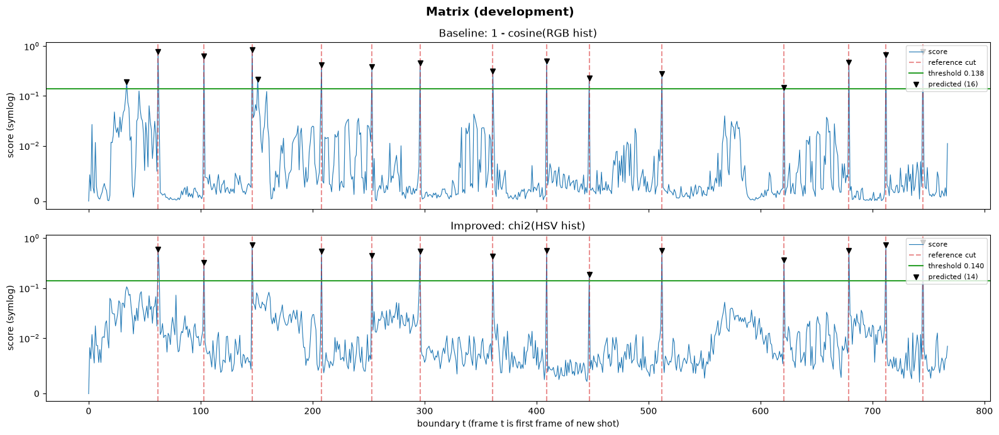

In [13]:
def plot_scores(video, gt, title, preds_base, preds_new, xlim=None):
    fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
    for ax, key, thr, preds, label in [
        (axes[0], "score_base", 0.138, preds_base, "Baseline: 1 - cosine(RGB hist)"),
        (axes[1], "score_new", FROZEN["T"], preds_new, "Improved: chi2(HSV hist)"),
    ]:
        sc = video[key]
        ax.plot(sc, lw=0.8, color="tab:blue", label="score")
        for i, g in enumerate(gt):
            ax.axvline(g, color="tab:red", ls="--", alpha=0.5, label="reference cut" if i == 0 else None)
        ax.axhline(thr, color="tab:green", lw=1.5, label=f"threshold {thr:.3f}")
        ax.plot(preds, sc[preds], "v", color="black", ms=6, label=f"predicted ({len(preds)})")
        ax.set_yscale("symlog", linthresh=0.01); ax.set_ylabel("score (symlog)")
        ax.set_title(label); ax.legend(loc="upper right", fontsize=8)
    axes[1].set_xlabel("boundary t (frame t is first frame of new shot)")
    if xlim: axes[1].set_xlim(*xlim)
    fig.suptitle(title, fontsize=14, fontweight="bold"); plt.tight_layout(); plt.show()

matrix_pred_base = detect_baseline(matrix["score_base"])
matrix_pred_new = detect_improved(matrix["score_new"], **FROZEN)
plot_scores(matrix, MATRIX_GT, "Matrix (development)", matrix_pred_base, matrix_pred_new)

## 2.3 Evaluation: one-to-one matching with tolerance ±1 frame

The assignment requires `|prediction − reference| ≤ 1` and one-to-one matching. Below, both sorted lists are scanned together and each prediction is matched to the first unmatched reference within ±1 frame. With a tolerance window on a line, this gives the maximum
number of one-to-one pairs. Matched and unmatched boundaries are listed, as required.

In [14]:
def match_events(pred, ref, tol=1):
    pred, ref = sorted(pred), sorted(ref)
    i = j = 0; pairs = []
    while i < len(pred) and j < len(ref):
        if abs(pred[i] - ref[j]) <= tol:
            pairs.append((pred[i], ref[j])); i += 1; j += 1
        elif pred[i] < ref[j]:
            i += 1
        else:
            j += 1
    mp, mr = {p for p, _ in pairs}, {r for _, r in pairs}
    tp, fp, fn = len(pairs), len(pred) - len(pairs), len(ref) - len(pairs)
    P = tp / (tp + fp) if tp + fp else 0.0
    R = tp / (tp + fn) if tp + fn else 0.0
    F1 = 2 * P * R / (P + R) if P + R else 0.0
    return dict(TP=tp, FP=fp, FN=fn, precision=P, recall=R, F1=F1, pairs=pairs,
                false_alarms=[p for p in pred if p not in mp], missed=[r for r in ref if r not in mr])

def report(name, res, show_lists=True):
    print(f"{name:34s} TP={res['TP']:3d} FP={res['FP']:3d} FN={res['FN']:3d} | "
          f"P={res['precision']:.3f} R={res['recall']:.3f} F1={res['F1']:.3f}")
    if show_lists:
        print(f"{'':34s} matched (pred->ref): {res['pairs']}")
        print(f"{'':34s} false alarms: {res['false_alarms']}")
        print(f"{'':34s} missed cuts : {res['missed']}")

print("=== MATRIX (development, parameters fitted here) ===")
report("Baseline (cos RGB, T=0.138, localmax)", match_events(matrix_pred_base, MATRIX_GT))
report("Improved (chi2 HSV + dominance)", match_events(matrix_pred_new, MATRIX_GT))

=== MATRIX (development, parameters fitted here) ===
Baseline (cos RGB, T=0.138, localmax) TP= 14 FP=  2 FN=  0 | P=0.875 R=1.000 F1=0.933
                                   matched (pred->ref): [(62, 62), (103, 103), (146, 146), (208, 208), (253, 253), (296, 296), (361, 361), (409, 409), (447, 447), (512, 512), (621, 621), (679, 679), (712, 712), (745, 745)]
                                   false alarms: [34, 151]
                                   missed cuts : []
Improved (chi2 HSV + dominance)    TP= 14 FP=  0 FN=  0 | P=1.000 R=1.000 F1=1.000
                                   matched (pred->ref): [(62, 62), (103, 103), (146, 146), (208, 208), (253, 253), (296, 296), (361, 361), (409, 409), (447, 447), (512, 512), (621, 621), (679, 679), (712, 712), (745, 745)]
                                   false alarms: []
                                   missed cuts : []


### Frozen pipeline applied to *Cosmos* (held-out, no retuning)

Cosmos: 3168 frames processed in 18.1 s


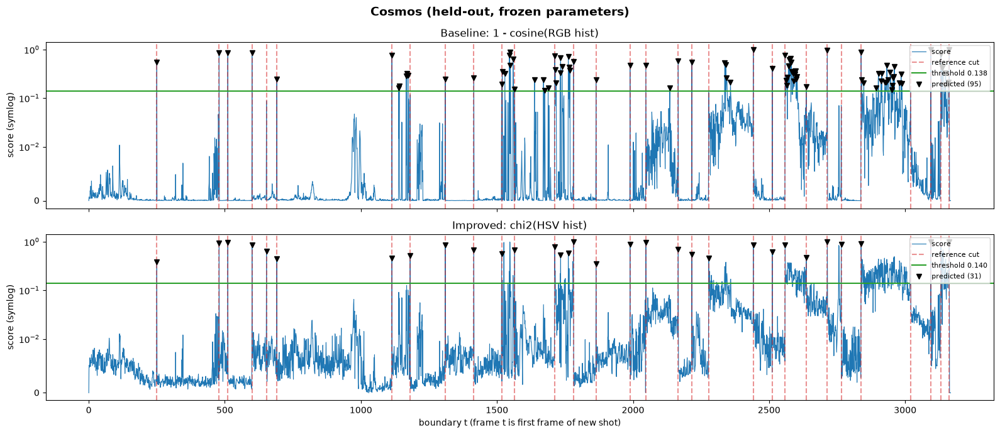

=== COSMOS (held-out, zero-shot) ===
Baseline (cos RGB, T=0.138, localmax) TP= 26 FP= 69 FN=  5 | P=0.274 R=0.839 F1=0.413
                                   matched (pred->ref): [(250, 250), (479, 479), (511, 511), (600, 600), (691, 691), (1114, 1114), (1310, 1310), (1415, 1415), (1517, 1517), (1565, 1565), (1712, 1712), (1781, 1781), (1864, 1864), (1989, 1989), (2047, 2047), (2166, 2166), (2216, 2216), (2442, 2442), (2512, 2512), (2559, 2559), (2637, 2637), (2714, 2714), (2838, 2838), (3094, 3094), (3131, 3131), (3162, 3162)]
                                   false alarms: [1139, 1141, 1166, 1168, 1173, 1520, 1529, 1545, 1547, 1549, 1559, 1638, 1671, 1675, 1688, 1714, 1717, 1732, 1734, 1739, 1762, 1765, 1768, 2135, 2337, 2341, 2344, 2358, 2563, 2565, 2568, 2571, 2573, 2575, 2579, 2581, 2583, 2588, 2591, 2594, 2596, 2598, 2600, 2603, 2840, 2848, 2894, 2902, 2911, 2914, 2925, 2930, 2933, 2938, 2945, 2950, 2953, 2956, 2958, 2960, 2979, 2985, 2987, 3135, 3139, 3146, 3148, 3158, 3160]
  

In [15]:
t0 = time.perf_counter()
cosmos = process_video(COSMOS)
print(f"Cosmos: {len(cosmos['thumbs'])} frames processed in {time.perf_counter() - t0:.1f} s")

cosmos_pred_base = detect_baseline(cosmos["score_base"])
cosmos_pred_new = detect_improved(cosmos["score_new"], **FROZEN)
plot_scores(cosmos, COSMOS_GT, "Cosmos (held-out, frozen parameters)", cosmos_pred_base, cosmos_pred_new)

print("=== COSMOS (held-out, zero-shot) ===")
report("Baseline (cos RGB, T=0.138, localmax)", match_events(cosmos_pred_base, COSMOS_GT))
report("Improved (chi2 HSV + dominance)", match_events(cosmos_pred_new, COSMOS_GT))

### Ablation: which change does the work?

Each component is switched on alone. For every row, T and α are re-derived **on Matrix** with the same
midpoint rules. If the score has no gap on Matrix (baseline cosine), the threshold 0.138 is kept.

In [16]:
def freeze_on_matrix(score):
    nc_ = non_cut_mask(len(score), MATRIX_GT)
    lo, hi = score[MATRIX_GT].min(), score[nc_].max()
    T_ = float(np.sqrt(lo * hi)) if lo > hi else 0.138
    d_ = dominance(score, W)
    risky_ = nc_ & (score >= 0.5 * lo)
    return T_, float(np.sqrt(d_[MATRIX_GT].min() * d_[risky_].max()))

print(f"{'variant':44s} {'Matrix F1':>9s} {'Cosmos TP/FP/FN':>16s} {'Cosmos F1':>9s}")
for label, key, use_dom in [("cos RGB + threshold/localmax (baseline)", "score_base", False),
                            ("chi2 HSV + threshold/localmax", "score_new", False),
                            ("cos RGB + dominance", "score_base", True),
                            ("chi2 HSV + dominance (improved)", "score_new", True)]:
    T_, a_ = freeze_on_matrix(matrix[key])
    det = (lambda s: detect_improved(s, T_, a_, W)) if use_dom else (lambda s: detect_baseline(s, T_))
    rm, rc = match_events(det(matrix[key]), MATRIX_GT), match_events(det(cosmos[key]), COSMOS_GT)
    print(f"{label:44s} {rm['F1']:9.3f} {rc['TP']:>6d}/{rc['FP']}/{rc['FN']:<6d} {rc['F1']:9.3f}")

variant                                      Matrix F1  Cosmos TP/FP/FN Cosmos F1
cos RGB + threshold/localmax (baseline)          0.933     26/69/5          0.413
chi2 HSV + threshold/localmax                    1.000     31/115/0          0.350
cos RGB + dominance                              1.000     21/2/10         0.778
chi2 HSV + dominance (improved)                  1.000     29/2/2          0.935


### Sensitivity (post-hoc check, **not** used to choose parameters)

How much would Cosmos F1 change if other values of T and α had been frozen? A flat table means the result does
not hinge on a lucky choice.

In [17]:
Ts, alphas = [0.08, 0.11, FROZEN["T"], 0.18, 0.22], [1.3, 1.5, FROZEN["alpha"], 2.0, 2.5]
print("Cosmos F1   " + "".join(f"T={t:<7.3f}" for t in Ts))
for a in alphas:
    print(f"alpha={a:<5.2f} " + "".join(
        f"{match_events(detect_improved(cosmos['score_new'], t, a, W), COSMOS_GT)['F1']:<9.3f}" for t in Ts))

Cosmos F1   T=0.080  T=0.110  T=0.140  T=0.180  T=0.220  
alpha=1.30  0.925    0.939    0.954    0.954    0.969    
alpha=1.50  0.969    0.969    0.969    0.969    0.969    
alpha=1.70  0.935    0.935    0.935    0.935    0.935    
alpha=2.00  0.900    0.900    0.900    0.900    0.900    
alpha=2.50  0.912    0.912    0.912    0.912    0.912    


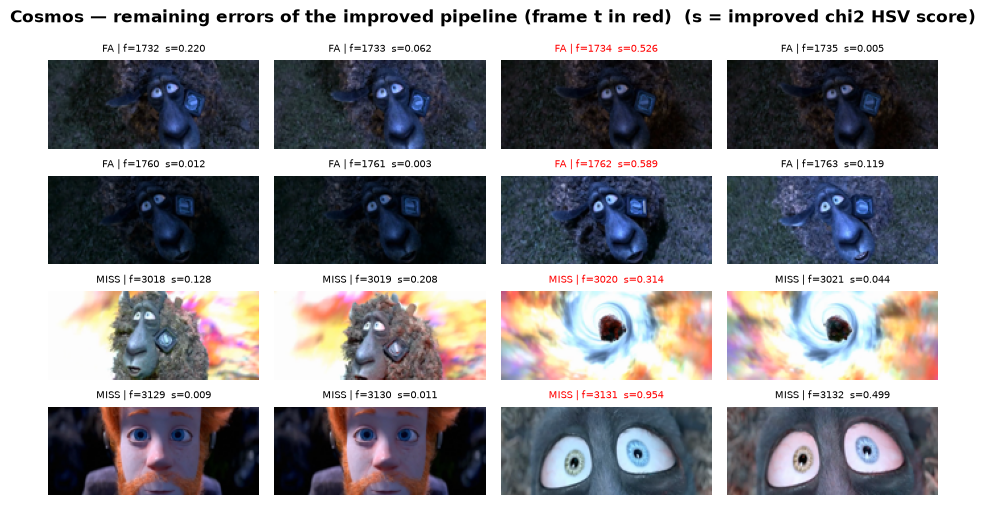

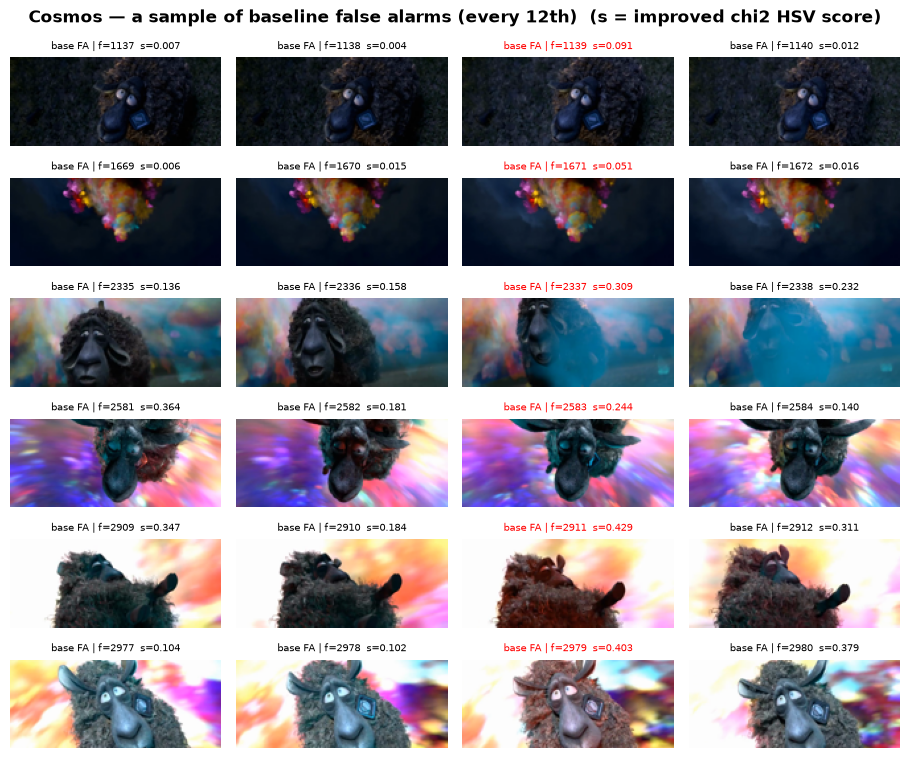

In [18]:
def show_events(video, events, title, before=2, after=2):
    if not events:
        print(f"{title}: none"); return
    cols = before + after
    fig, axes = plt.subplots(len(events), cols, figsize=(2.3 * cols, 1.3 * len(events)), squeeze=False)
    for r, (t, tag) in enumerate(events):
        for c, f in enumerate(range(t - before, t + after)):
            ax = axes[r, c]; ax.axis("off")
            if 0 <= f < len(video["thumbs"]):
                ax.imshow(video["thumbs"][f])
                ax.set_title(f"{tag} | f={f}  s={video['score_new'][f]:.3f}", fontsize=7,
                             color="red" if f == t else "black")
    fig.suptitle(title + "  (s = improved chi2 HSV score)", fontweight="bold"); plt.tight_layout(); plt.show()

res_new = match_events(cosmos_pred_new, COSMOS_GT)
res_base = match_events(cosmos_pred_base, COSMOS_GT)
show_events(cosmos, [(t, "FA") for t in res_new["false_alarms"]] + [(t, "MISS") for t in res_new["missed"]],
            "Cosmos — remaining errors of the improved pipeline (frame t in red)")
show_events(cosmos, [(t, "base FA") for t in res_base["false_alarms"][::12]],
            "Cosmos — a sample of baseline false alarms (every 12th)")

### Discussion of Part 2

**Matrix.** <br>
With cosine distance on the RGB histogram, the weakest true cut (boundary 621, score 0.147) is below the strongest non-cut (0.218). **No threshold can give a perfect result.** The threshold 0.138 found all 14 cuts but also 2 false alarms (34 and 151). Changing to HSV + χ² opens a clean gap on Matrix (0.185 vs 0.106), so the threshold no longer needs to be set by eye.

**Cosmos, baseline (F1 = 0.413).** <br>
Recall was good (26/31) but there were 69 false alarms. *Cosmos Laundromat* is an animated short about a sheep on a night-time island, full of lighting effects. Inspecting the frames shows three sources:
1. **light flicker in dark night shots** of the sheep (≈1137–1768), where a blinking device on its collar changes the
   global brightness;
2. **psychedelic colour-flash sequences** (≈2561–2603, 2838–2987), where every few frames the whole palette changes
   while the camera stays on the same subject;
3. **the flashing eye close-up** at the end (≈3133–3160).

All three produce *bursts* of high scores, and a local-maximum test lets one detection through every 2–3 frames.
The 5 missed cuts (653, 1181, 2278, 2765, 3020) are mostly **dark-to-dark cuts**. Cosine on a histogram dominated by the "black" bin barely moves (e.g. 0.087 at 653, 0.071 at 2765).

**Cosmos, improved.** <br>
Each change targets one failure:
* χ² on the HSV histogram raises the dark-to-dark cuts above T, because small non-black bins are no longer
  ignored. Alone it brings recall to 31/31 but even more false alarms, since flashes also change hue.
* the dominance test removes bursts (flashes, flicker), because no frame inside a burst stands out from its
  ±6-frame neighbourhood. Alone, on the cosine score, it removes most false alarms but loses recall.
* together: see the table above (TP 29, FP 2, FN 2, **F1 = 0.935**).

**Remaining errors and the precision–recall trade-off.** <br>
Both remaining misses are cuts *next to another large change*, so they do not dominate their ±6-frame window. At 3020 (cut into the cosmic-swirl shot) the frames just before are already changing colour (score 0.208 at 3019). At 3131 (cut to the eyes close-up) the next frame changes colour strongly again (0.499 at 3132) and the flashing-eyes burst follows.<br>
The two false alarms (1734, 1762) are single-frame lighting jumps on the dark sheep shot that look like a cut to a colour histogram. Raising α trades recall for precision: at α = 2.5 the misses go up, and at α = 1.3 more flicker frames pass. The sensitivity table shows Cosmos F1 stays within about 0.90–0.97 for T from 0.08 to 0.22 and α from 1.3 to 2.5. The result does not depend on a finely tuned value. <br>
The table also shows that for α ≥ 1.5 the F1 does not depend on T at all: on Cosmos, every frame that dominates its ±6 neighbourhood already scores above 0.22, so the dominance test makes the decisions. T only acts as a safety floor for nearly static shots, where a tiny score can still dominate an even tinier neighbourhood (for example 0.01 surrounded by 0.001). It starts to matter at α = 1.3. Note also that α = 1.5 would have given a higher Cosmos F1 (0.969) than the frozen α = 1.70. It was not used, because choosing it by looking at Cosmos would break the held-out protocol.

**Honesty note on the held-out protocol.** <br>
The baseline was evaluated on Cosmos first, and its Cosmos errors were inspected while designing the improved pipeline. The *candidate* changes (HSV, χ², temporal dominance) are standard remedies for flashes and dark scenes. The *selection* and all numeric parameters come from Matrix-only rules, but the Cosmos score of the improved pipeline is not as "blind" as a truly first-time test would be.

## 2.4 Storyboard

For each detected shot `[start, end]` the storyboard shows: the frame **before** the start (last frame of the
previous shot), the **first** frame, a **representative** frame, the **last** frame and the frame **after** the end.
All are labelled with their index, so each boundary can be checked visually.

**Representative frame = the frame closest to the shot's mean HVS histogram**: the frame whose histogram has the smallest χ² distance to the mean histogram of the shot. Why:
* it is the frame that is *most typical* of the whole shot's colours and content. For a shot with a pan or zoom it
  falls in the middle of the motion rather than at an extreme;
* unlike the middle frame by time, it avoids transient frames (a flash or a passing object) because those are far
  from the mean;
* it reuses features already computed for detection, so it costs nothing extra.

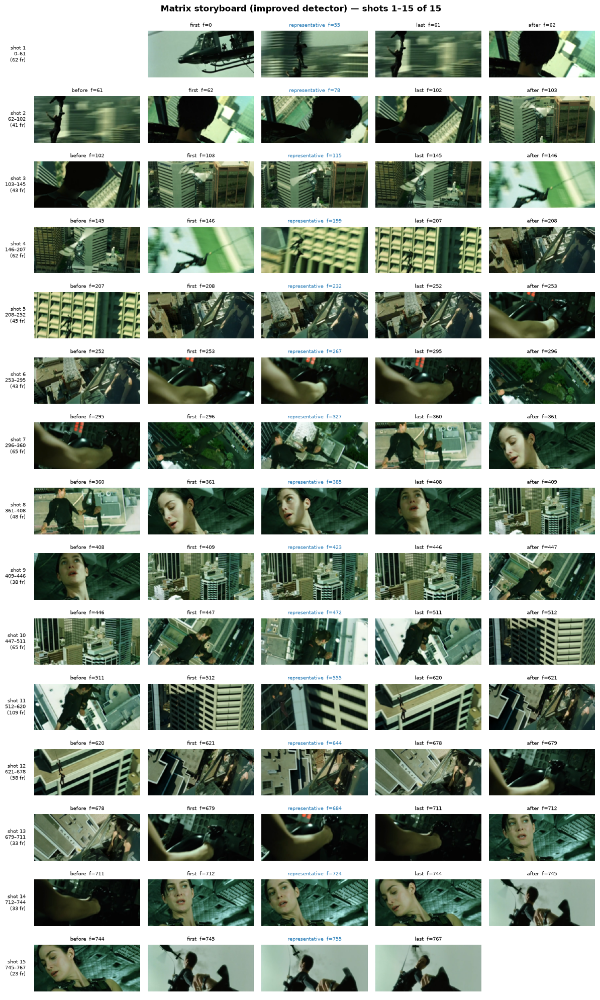

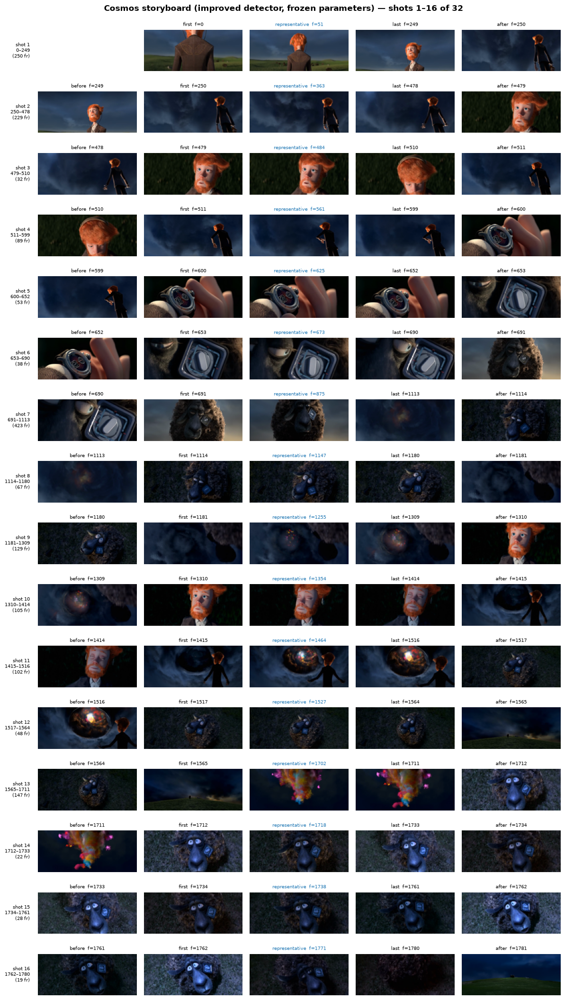

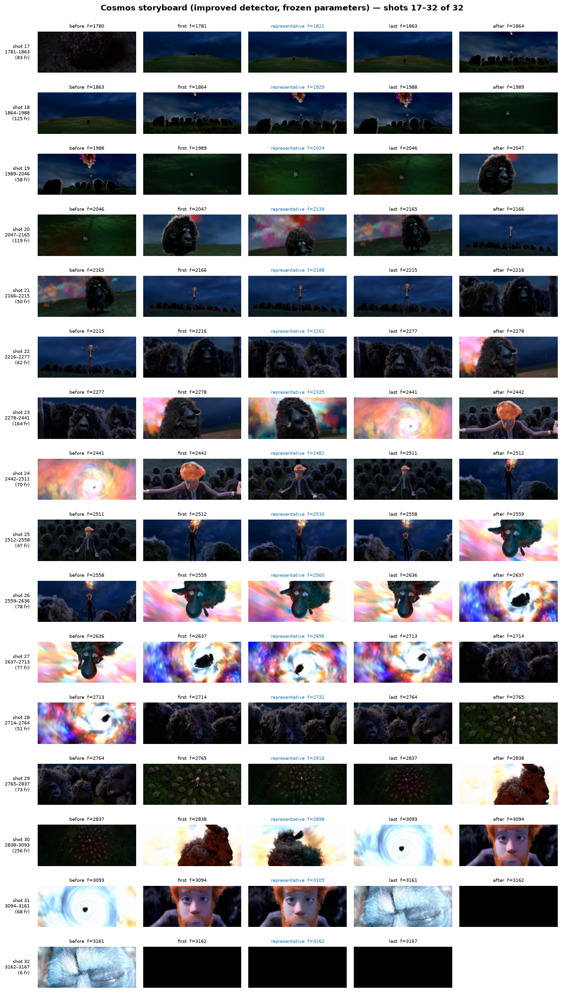

In [19]:
def shots_from_boundaries(boundaries, n_frames):
    starts = [0] + sorted(boundaries)
    ends = [b - 1 for b in sorted(boundaries)] + [n_frames - 1]
    return list(zip(starts, ends))

def representative_frame(hsv, start, end):
    H = hsv[start:end + 1]
    return start + int(np.argmin(chi2_distance(H, H.mean(0, keepdims=True))))

def first_middle_last(n_shots, n=4):
    # Shot indices for the first n, middle n and last n shots (no duplicates for short videos)
    mid = max(0, n_shots // 2 - n // 2)
    return sorted(set(range(min(n, n_shots))) | set(range(mid, min(mid + n, n_shots)))
                  | set(range(max(0, n_shots - n), n_shots)))

def storyboard(video, boundaries, title, shots_per_fig=16, select=None):
    n = len(video["thumbs"])
    shots = shots_from_boundaries(boundaries, n)
    numbered = [(i, sh) for i, sh in enumerate(shots) if select is None or i in select]
    cols = ["before", "first", "representative", "last", "after"]
    for k in range(0, len(numbered), shots_per_fig):
        chunk = numbered[k:k + shots_per_fig]
        fig, axes = plt.subplots(len(chunk), 5, figsize=(12, 1.35 * len(chunk)), squeeze=False)
        for r, (shot_no, (a, b)) in enumerate(chunk):
            rep = representative_frame(video["hsv"], a, b)
            for c, f in enumerate([a - 1, a, rep, b, b + 1]):
                ax = axes[r, c]; ax.axis("off")
                if 0 <= f < n:
                    ax.imshow(video["thumbs"][f])
                    ax.set_title(f"{cols[c]}  f={f}", fontsize=7, color="tab:blue" if c == 2 else "black")
            axes[r, 0].text(-0.08, 0.5, f"shot {shot_no + 1}\n{a}–{b}\n({b - a + 1} fr)", fontsize=7,
                            transform=axes[r, 0].transAxes, ha="right", va="center")
        shown = f"shots {chunk[0][0] + 1}–{chunk[-1][0] + 1}" if select is None else "first / middle / last shots"
        fig.suptitle(f"{title} — {shown} of {len(shots)}", fontweight="bold")
        plt.tight_layout(rect=(0, 0, 1, 0.985)); plt.show()

storyboard(matrix, matrix_pred_new, "Matrix storyboard (improved detector)")
storyboard(cosmos, cosmos_pred_new, "Cosmos storyboard (improved detector, frozen parameters)")

## 2.5 Robustness check on the other clips (suggested in class)

The teacher suggested in class to also run the pipeline on the other provided clips, to check that it is robust.
The assignment gives reference cuts only for *Matrix* and *Cosmos*, so I **annotated the three other clips by hand**:

| Clip | Frames | Content | Reference cuts | Ignore zones |
|---|---|---|---|---|
| *Man with a Movie Camera* (1929) | 1649 @ 29.97 fps | black & white, very fast montage | 20 | fast train montage, black-frame flicker |
| *Entr'acte*, hearse chase (1924) | 5065 @ 29.97 fps | black & white, tracking shots, poles passing the lens | 58 | 2 dissolves, 2 unclear transitions |
| *Vertigo*, dream scene (1958) | 2375 @ 25 fps | colour, deliberate colour-light pulses, animation | 9 | animated passages, dissolves |

**Annotation protocol.** Contact sheets of every 3rd/4th frame were inspected **without looking at any detector
output**, to find every change of shot. Each cut was then located at the exact frame on strips of consecutive frames.
The silent films were converted from 16–24 fps film to 29.97 fps, so a cut often has **one blended frame** (half old
shot, half new). That blended frame is labelled as the boundary, and the ±1 evaluation tolerance also accepts the next
clean frame. Passages where a hard cut cannot be defined reliably (dissolves, animation, single black frames, montage
of 1–3-frame shots) are **ignore zones**: predictions inside them (±1) are neither true nor false positives. Only
hard cuts count, as in the assignment. This is a single annotator's labelling (mine), so treat the numbers as indicative.

**Protocol.** Both detectors run **exactly as frozen on Matrix**: no parameter is changed.

In [20]:
EXTRA = {
    "ManWithAMovieCamera": dict(
        path=VIDEO_DIR / "Extrait2-ManWithAMovieCamera.m4v",
        cuts=[157, 203, 387, 518, 568, 667, 958, 968, 994, 1001, 1027, 1044, 1104, 1134, 1253, 1276, 1289, 1310,
              1381, 1590],
        ignore=[(959, 962), (1045, 1052), (1140, 1251), (1440, 1589)]),
    "Entracte": dict(
        path=VIDEO_DIR / "Extrait4-Entracte-Poursuite_Corbillard(358p).m4v",
        cuts=[178, 243, 294, 440, 494, 623, 660, 976, 1053, 1153, 1215, 1409, 1460, 1646, 1919, 2086, 2135, 2168,
              2238, 2351, 2399, 2599, 2659, 2778, 2826, 2876, 2984, 3056, 3081, 3193, 3238, 3352, 3405, 3514, 3636,
              3757, 3797, 3828, 3890, 3925, 3933, 3995, 4099, 4174, 4347, 4382, 4447, 4511, 4520, 4620, 4664, 4713,
              4799, 4854, 4882, 4900, 4919, 4984],
        ignore=[(2560, 2575), (3046, 3054), (3564, 3575), (4780, 4797)]),
    "Vertigo": dict(
        path=VERTIGO,
        cuts=[284, 1184, 1351, 1660, 1838, 1976, 2025, 2136, 2211],
        ignore=[(100, 115), (775, 1060), (1510, 1516), (1840, 1974), (2288, 2330)]),
}

def drop_ignored(pred, zones):
    return [t for t in pred if not any(a - 1 <= t <= b + 1 for a, b in zones)]

extra_videos, extra_results = {}, {}
for name, cfg in EXTRA.items():
    t0 = time.perf_counter()
    v = process_video(cfg["path"], thumb_width=120)
    v["mean_color_dev"] = float(np.mean([np.abs(th.astype(int) - th.mean(2, keepdims=True)).mean()
                                         for th in v["thumbs"][::25]]))
    extra_videos[name] = v
    pb = drop_ignored(detect_baseline(v["score_base"]), cfg["ignore"])
    pn = drop_ignored(detect_improved(v["score_new"], **FROZEN), cfg["ignore"])
    extra_results[name] = {"before": match_events(pb, cfg["cuts"]), "after": match_events(pn, cfg["cuts"]),
                           "pred_after": detect_improved(v["score_new"], **FROZEN)}
    print(f"{name}: {len(v['thumbs'])} frames in {time.perf_counter() - t0:.1f} s, "
          f"mean colour deviation {v['mean_color_dev']:.1f} (0 = grey)")

print()
pooled = {"before": [0, 0, 0], "after": [0, 0, 0]}
for name in EXTRA:
    for which in ("before", "after"):
        r = extra_results[name][which]
        report(f"{name} {which}", r, show_lists=False)
        pooled[which] = [x + y for x, y in zip(pooled[which], (r["TP"], r["FP"], r["FN"]))]
    print(f"{'':34s} missed by 'after': {extra_results[name]['after']['missed']}")
print()
for which, (tp, fp, fn) in pooled.items():
    P, R = tp / (tp + fp), tp / (tp + fn)
    print(f"POOLED over the 3 clips, {which:6s}: TP={tp} FP={fp} FN={fn} | P={P:.3f} R={R:.3f} F1={2 * P * R / (P + R):.3f}")

ManWithAMovieCamera: 1649 frames in 3.5 s, mean colour deviation 1.0 (0 = grey)
Entracte: 5065 frames in 18.6 s, mean colour deviation 1.0 (0 = grey)
Vertigo: 2375 frames in 8.5 s, mean colour deviation 18.9 (0 = grey)

ManWithAMovieCamera before         TP= 14 FP= 32 FN=  6 | P=0.304 R=0.700 F1=0.424
ManWithAMovieCamera after          TP=  5 FP=  4 FN= 15 | P=0.556 R=0.250 F1=0.345
                                   missed by 'after': [157, 518, 568, 667, 958, 968, 994, 1044, 1104, 1134, 1253, 1276, 1289, 1381, 1590]
Entracte before                    TP= 49 FP= 78 FN=  9 | P=0.386 R=0.845 F1=0.530
Entracte after                     TP= 41 FP= 57 FN= 17 | P=0.418 R=0.707 F1=0.526
                                   missed by 'after': [178, 294, 623, 660, 976, 1460, 2086, 2168, 2238, 2778, 3352, 3514, 3757, 3933, 4174, 4620, 4854]
Vertigo before                     TP=  7 FP=150 FN=  2 | P=0.045 R=0.778 F1=0.084
Vertigo after                      TP=  3 FP=  1 FN=  6 | P=0.750 R=0.333 F

ManWithAMovieCamera  cut   518: 0.00  0.00  0.05  [0.35]  0.27  0.04  0.00
ManWithAMovieCamera  cut   667: 0.01  0.02  0.00  [0.11]  0.10  0.01  0.00
ManWithAMovieCamera  cut  1289: 0.03  0.00  0.03  [0.04]  0.03  0.03  0.03
Vertigo              cut  1184: 0.22  0.42  0.41  [0.45]  0.00  0.00  0.00
Vertigo              cut  1351: 0.01  0.01  0.01  [0.98]  0.10  0.13  0.60
Vertigo              cut  1838: 0.02  0.85  0.04  [0.81]  0.01  0.00  0.00


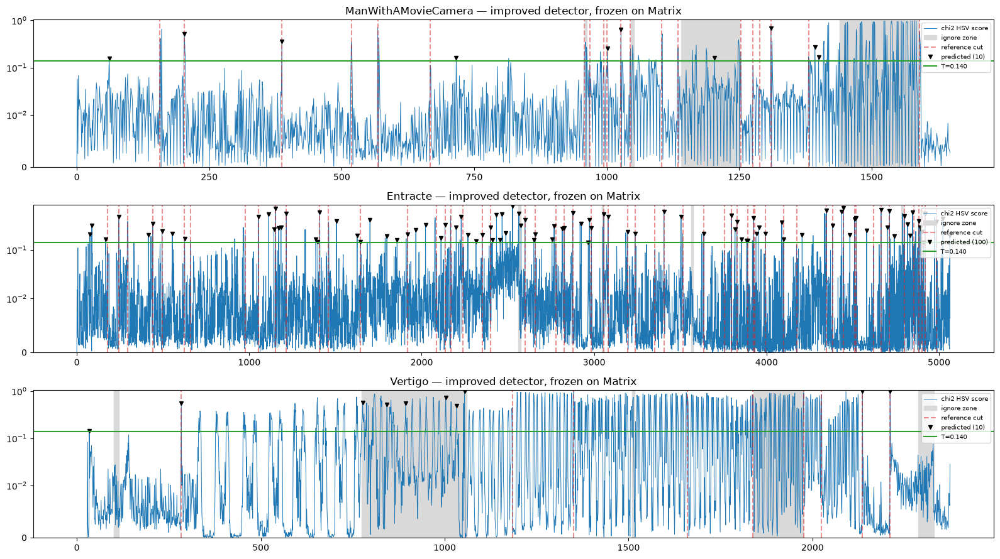

In [21]:
# Why does the frozen detector miss cuts here? Score neighbourhoods around some missed cuts (t-3 .. t+3)
for name, cuts in [("ManWithAMovieCamera", [518, 667, 1289]), ("Vertigo", [1184, 1351, 1838])]:
    s = extra_videos[name]["score_new"]
    for c in cuts:
        vals = "  ".join(f"{'[' if t == c else ''}{s[t]:.2f}{']' if t == c else ''}" for t in range(c - 3, c + 4))
        print(f"{name:20s} cut {c:5d}: {vals}")

fig, axes = plt.subplots(3, 1, figsize=(16, 9))
for ax, name in zip(axes, EXTRA):
    v, cfg = extra_videos[name], EXTRA[name]
    ax.plot(v["score_new"], lw=0.7, label="chi2 HSV score")
    for a, b in cfg["ignore"]:
        ax.axvspan(a, b, color="0.85", label="ignore zone" if (a, b) == cfg["ignore"][0] else None)
    for i, g in enumerate(cfg["cuts"]):
        ax.axvline(g, color="tab:red", ls="--", alpha=0.5, label="reference cut" if i == 0 else None)
    p = extra_results[name]["pred_after"]
    ax.plot(p, v["score_new"][p], "v", color="black", ms=5, label=f"predicted ({len(p)})")
    ax.axhline(FROZEN["T"], color="tab:green", label=f"T={FROZEN['T']:.3f}")
    ax.set_yscale("symlog", linthresh=0.01); ax.set_ylim(bottom=0)
    ax.set_title(f"{name} — improved detector, frozen on Matrix")
    ax.legend(loc="upper right", fontsize=7)
plt.tight_layout(); plt.show()

### What the other clips show

The pooled table above is the honest transfer result. A detector tuned on one modern colour action clip **does not
carry over** to footage with different properties, and the reasons are specific:

* **Black & white film (*Man with a Movie Camera*, *Entr'acte*).** The HSV histogram was chosen so that *hue* drives
  the score. On grey frames hue and saturation are empty, so the 16×4×4 histogram collapses to **4 brightness bins**.
  Many cuts between two similarly grey shots score only ≈ 0.1 (below T = 0.140).
* **Blended frames from the frame-rate conversion.** The jump of a cut is split over two consecutive boundaries
  (e.g. 0.35 then 0.27 at 518), so the cut never "dominates" its ±6 neighbourhood. This is why the improved detector
  has *lower* recall than the simple baseline on *Man with a Movie Camera*.
* **Cuts timed on light pulses (*Vertigo*).** Hitchcock places cuts right next to colour pulses, so a cut scoring 0.98
  sits next to pulse frames scoring 0.4–0.9. The dominance rule removes almost all 150 pulse false alarms of the
  baseline, but also 6 of the 9 cuts.
* *Entr'acte* is the most balanced case: both detectors reach F1 ≈ 0.53. The baseline has more recall, the improved
  detector fewer false alarms, mainly from trees and poles passing in front of the lens in tracking shots.

**Fixes tried and rejected (exploratory, after seeing these clips).** (1) Also comparing frame t−1 with t+1 (to skip a
blended frame) and ignoring the ±1 neighbours in the dominance test. (2) More brightness bins (16×4×16). (3) A
structure-based score (correlation of 32×24 grey thumbnails). Each was re-frozen on Matrix with the same rules. None
improved all clips: each gained on one clip and lost on Matrix/Cosmos or another clip, so the frozen detector above is
kept. These experiments were exploratory and are not kept in the notebook; section 2.6 below compares the main frame-to-frame alternatives in a reproducible way.

**Lesson.** One development clip cannot cover the variety of real footage. A robust detector would need either a
development set that includes black-and-white and flash-heavy material, or a richer representation (e.g. CNN
features) whose behaviour does not depend on colour.

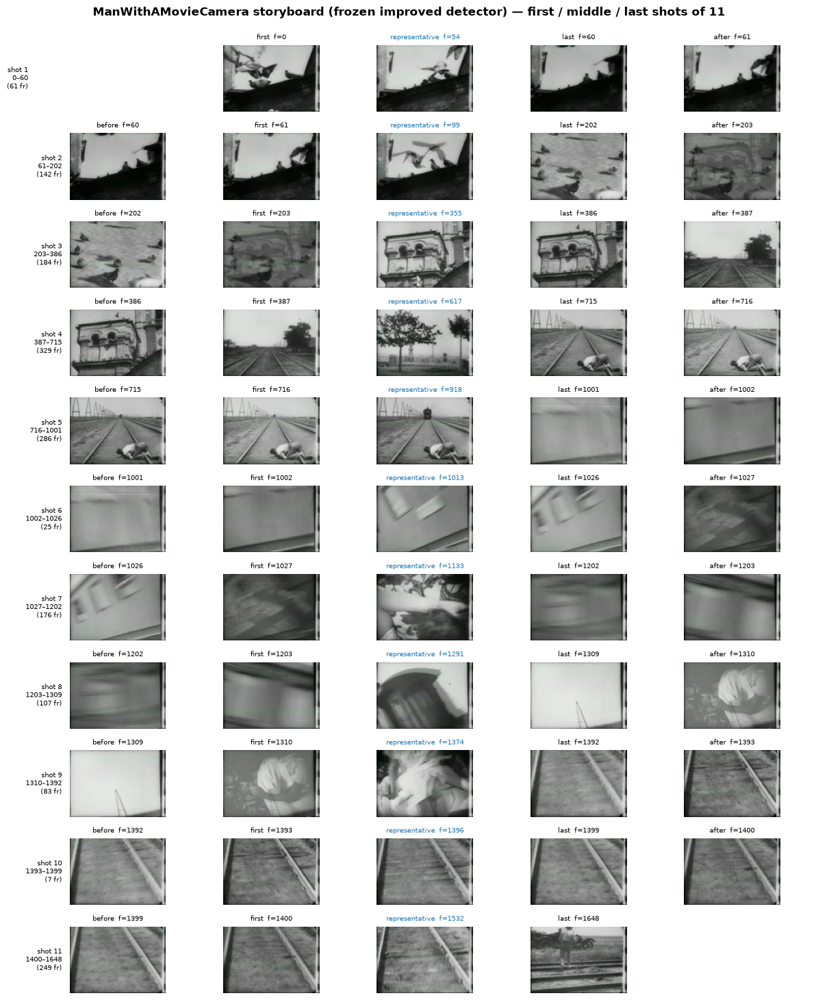

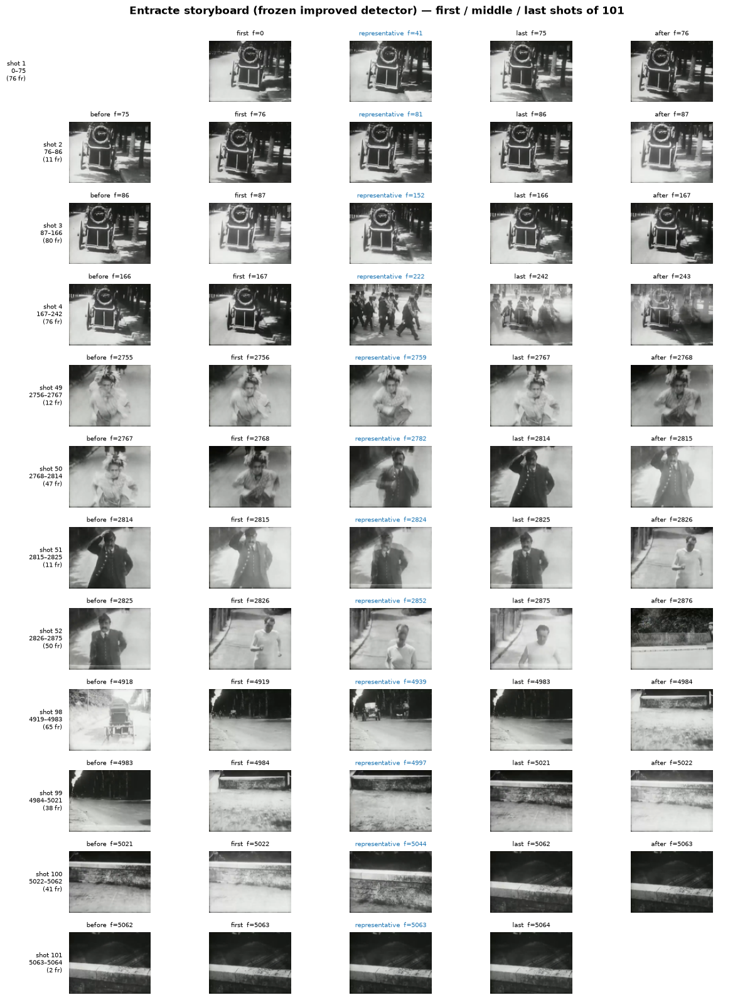

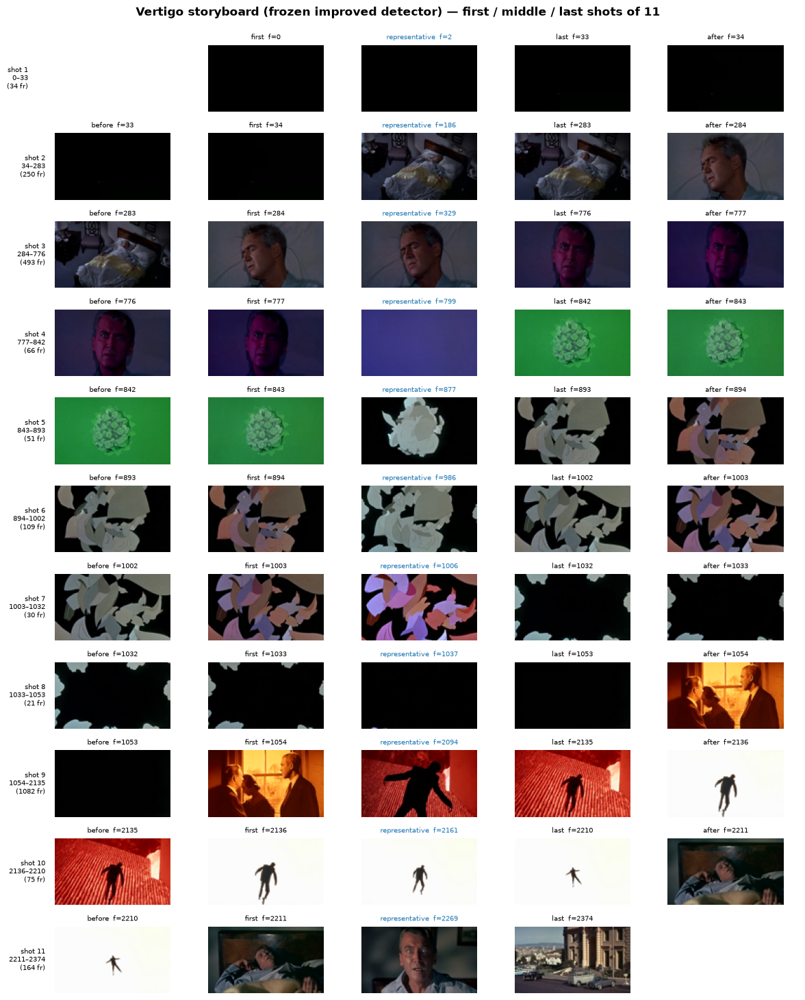

In [22]:
# Storyboards of the first, middle and last shots (as suggested in class), improved detector
for name in EXTRA:
    v = extra_videos[name]
    b = extra_results[name]["pred_after"]
    sel = first_middle_last(len(b) + 1, n=4)
    storyboard(v, b, f"{name} storyboard (frozen improved detector)", select=sel)

### 2.6 Frame-to-frame options: adjacent frames, video statistics, n before vs n after

The detector above compares **adjacent frames** (t−1 vs t) and uses the ±w neighbourhood only in the decision
(dominance). Two other common ways to use time are compared here, on the same HSV histograms and χ² distance:

* **Global average:** the threshold adapts to each video. The adjacent score is turned into a z-score
  (score − mean) / std computed over that video, and a cut must have z ≥ k and be a local maximum in ±w.
* **n frames before vs n frames after:** the score at t is the χ² distance between the *mean* histogram of
  frames t−n … t−1 and the mean histogram of frames t … t+n−1, followed by a threshold and a local maximum in
  ±max(w, n). Averaging n frames should smooth one-frame flicker and flashes.

Every option is frozen on Matrix with the same midpoint rule as in 2.2, then applied unchanged to the other clips.
For the window score, a cut makes the score ramp up over ±n frames, so only frames more than n away from a
reference cut count as non-cuts.


In [23]:
# Frame-to-frame options: same HSV histograms and chi2 distance, every option frozen on Matrix only
def window_scores(hsv, n):
    # chi2 between the mean histogram of frames t-n..t-1 and the mean histogram of frames t..t+n-1
    c = np.vstack([np.zeros((1, hsv.shape[1])), np.cumsum(hsv, axis=0)])
    s = np.zeros(len(hsv))
    for t in range(1, len(hsv)):
        a, b = max(0, t - n), min(len(hsv), t + n)
        pre, post = (c[t] - c[a]) / (t - a), (c[b] - c[t]) / (b - t)
        s[t] = chi2_distance(pre[None], post[None])[0]
    return s

def is_local_max(s, w):
    return np.array([t > 0 and s[t] == s[max(1, t - w):t + w + 1].max() for t in range(len(s))])

def zscore(s):
    return (s - s[1:].mean()) / (s[1:].std() + 1e-12)

def freeze_global_average():
    # Adjacent score, but the threshold adapts to each video: z = (score - mean) / std of that video
    z = zscore(adjacent_scores(matrix["hsv"], chi2_distance))
    nc = non_cut_mask(len(z), MATRIX_GT)
    k = float((z[MATRIX_GT].min() + z[nc].max()) / 2)   # midpoint of the z gap on Matrix
    def detect(hsv):
        s = adjacent_scores(hsv, chi2_distance)
        return [int(t) for t in np.flatnonzero((zscore(s) >= k) & is_local_max(s, W))]
    return detect, f"k = {k:.2f}"

def freeze_window(n):
    # n frames before vs n frames after; a window score ramps up over +-n frames around a cut,
    # so only frames further than n from a reference cut count as non-cuts
    s = window_scores(matrix["hsv"], n)
    nc = non_cut_mask(len(s), MATRIX_GT, tol=n)
    lo, hi = s[MATRIX_GT].min(), s[nc].max()
    T_n = float(np.sqrt(lo * hi))
    def detect(hsv):
        s = window_scores(hsv, n)
        return [int(t) for t in np.flatnonzero((s >= T_n) & is_local_max(s, max(W, n)))]
    return detect, f"T = {T_n:.3f}" + ("" if lo > hi else " (no gap)")

options = {"adjacent + dominance (frozen)": (lambda hsv: detect_improved(adjacent_scores(hsv, chi2_distance), **FROZEN), "see 2.2"),
           "adjacent + video mean/std": freeze_global_average()}
for n in (2, 3, 5):
    options[f"{n} before vs {n} after"] = freeze_window(n)

clips = [("Matrix", matrix["hsv"], MATRIX_GT, []), ("Cosmos", cosmos["hsv"], COSMOS_GT, [])] + \
        [(name, extra_videos[name]["hsv"], cfg["cuts"], cfg["ignore"]) for name, cfg in EXTRA.items()]
print(f"{'option':30s} {'frozen value':18s}" + "".join(f"{c[0][:10]:>15s}" for c in clips) + "  3 others F1")
for name, (detect, param) in options.items():
    cells, pooled = [], np.zeros(3, int)
    for clip, hsv, gt, ignore in clips:
        r = match_events(drop_ignored(detect(hsv), ignore), gt)
        cells.append(f"{r['TP']}/{r['FP']}/{r['FN']} {r['F1']:.2f}")
        if clip not in ("Matrix", "Cosmos"):
            pooled += (r["TP"], r["FP"], r["FN"])
    tp, fp, fn = pooled
    print(f"{name:30s} {param:18s}" + "".join(f"{c:>15s}" for c in cells) + f"   {2 * tp / (2 * tp + fp + fn):12.3f}")
print("\ncells: TP/FP/FN F1")


option                         frozen value               Matrix         Cosmos     ManWithAMo       Entracte        Vertigo  3 others F1
adjacent + dominance (frozen)  see 2.2               14/0/0 1.00    29/2/2 0.94    5/4/15 0.34  41/57/17 0.53     3/1/6 0.46          0.495
adjacent + video mean/std      k = 1.63              14/0/0 1.00   31/24/0 0.72    7/3/13 0.47   50/84/8 0.52    6/57/3 0.17          0.429
2 before vs 2 after            T = 0.194 (no gap)    13/2/1 0.90   31/29/0 0.68    9/5/11 0.53  45/55/13 0.57    6/79/3 0.13          0.420
3 before vs 3 after            T = 0.252 (no gap)    13/3/1 0.87   31/17/0 0.78    6/2/14 0.43  35/35/23 0.55    6/79/3 0.13          0.376
5 before vs 5 after            T = 0.315 (no gap)    12/4/2 0.80    31/9/0 0.87    4/2/16 0.31  30/23/28 0.54    7/85/2 0.14          0.345

cells: TP/FP/FN F1


**What the comparison shows.**

* **Global average (z-score threshold).** Normalising by each video's own mean and std makes the threshold follow
  the overall score level: it finds every Cosmos cut (31/31) and 2 more cuts on the grey *Man with a Movie Camera*,
  where absolute scores are low. But a local-maximum test alone cannot remove bursts: each flash or flicker burst
  still lets one frame through (24 false alarms on Cosmos, 57 on the colour pulses of *Vertigo*).
* **n frames before vs n after.** Averaging over n frames does smooth flicker: on Cosmos the false alarms drop
  from 29 (n = 2) to 17 (n = 3) to 9 (n = 5) while recall stays at 31/31. But it has two costs. (1) On Matrix there
  is **no gap** any more between cuts and non-cuts: fast camera motion changes the colour content steadily over
  several frames, and the window adds these changes up, so the threshold is a compromise and Matrix F1 drops to
  0.80–0.90. (2) A window longer than a shot mixes two shots, so very short shots are missed: on the fast montage
  of *Man with a Movie Camera* recall falls from 9 (n = 2) to 4 (n = 5). Light pulses on *Vertigo* last several
  frames, so averaging does not remove them.
* **Choice.** Selected on Matrix, the development set, the adjacent score with the dominance test is the only
  option with a clean separation (F1 = 1.00, no false alarm), so it stays the frozen detector. It also gives the best
  pooled F1 on the three other clips (0.495). The n = 5 window is close on Cosmos (F1 0.87 vs 0.94), but choosing it
  by looking at Cosmos would break the held-out protocol.

The two ideas are complementary: dominance asks whether *one frame-to-frame jump* stands out from its neighbours,
while the window compares *the content before and after*. A detector combining both is a natural next step.


### Optional: interactive explorer

The static storyboards above are the deliverable. This widget only helps browsing (it uses the cached thumbnails,
so it does not decode the video again). Choose any of the five videos, the detector (before/after) and a shot.
It does not render in a static export.

In [24]:
try:
    import ipywidgets as widgets
    import matplotlib.pyplot as plt
    from IPython.display import display
    
    all_videos = {"Matrix": matrix, "Cosmos": cosmos, **extra_videos}
    def boundaries_for(name, detector):
        v = all_videos[name]
        return detect_improved(v["score_new"], **FROZEN) if detector == "after" else detect_baseline(v["score_base"])

    video_dd = widgets.Dropdown(options=list(all_videos), description="Video")
    det_dd = widgets.Dropdown(options=["after", "before"], description="Detector")
    shot_sl = widgets.IntSlider(0, 0, len(boundaries_for("Matrix", "after")), description="Shot #",
                                continuous_update=False)

    def _update_range(*_):
        # The slider range follows the number of shots of the selected video / detector
        shot_sl.max = len(boundaries_for(video_dd.value, det_dd.value))
        
    video_dd.observe(_update_range, "value")
    det_dd.observe(_update_range, "value")

    def _show(video, detector, shot):
        v = all_videos[video]
        shots = shots_from_boundaries(boundaries_for(video, detector), len(v["thumbs"]))
        shot = min(shot, len(shots) - 1)
        a, e = shots[shot]
        rep = representative_frame(v["hsv"], a, e)
        
        fig, axes = plt.subplots(1, 5, figsize=(14, 2.4))
        for ax, f, lab in zip(axes, [a - 1, a, rep, e, e + 1], ["before", "first", "representative", "last", "after"]):
            ax.axis("off")
            if 0 <= f < len(v["thumbs"]):
                ax.imshow(v["thumbs"][f])
                ax.set_title(f"{lab} f={f}", fontsize=9)
        fig.suptitle(f"{video} [{detector}]: shot {shot + 1}/{len(shots)} ({a}–{e})")
        

    # interactive_output automatically manages output clearing and synchronization
    plot_output = widgets.interactive_output(_show, {'video': video_dd, 'detector': det_dd, 'shot': shot_sl})

    # Display the UI controls and the synchronized plot output box together
    display(video_dd, det_dd, shot_sl, plot_output)

except ImportError:
    print("ipywidgets not installed; skip")

Dropdown(description='Video', options=('Matrix', 'Cosmos', 'ManWithAMovieCamera', 'Entracte', 'Vertigo'), valu…

Dropdown(description='Detector', options=('after', 'before'), value='after')

IntSlider(value=0, continuous_update=False, description='Shot #', max=14)

Output()